In [5]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings

# Suppress warnings
warnings.filterwarnings("ignore")

# --- Configuration ---
INPUT_FILE = '../data/processed/features.csv'
OUTPUT_FILE = '../results/metrics/xgboost_results.csv'

def mean_absolute_percentage_error(y_true, y_pred): 
    """Calculates MAPE (Mean Absolute Percentage Error)"""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def main():
    print("Loading data...")
    try:
        df = pd.read_csv(INPUT_FILE)
    except FileNotFoundError:
        print(f"Error: {INPUT_FILE} not found.")
        return

    # 1. Data Prep
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(['Store', 'Date'])

    # 2. Feature Selection
    # Exclude ID cols and Target cols
    exclude_cols = ['Store', 'Date', 'Weekly_Sales', 'sales_log1p']
    
    # Select all other numeric columns
    feature_cols = [c for c in df.columns if c not in exclude_cols]
    feature_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(df[c])]
    
    print(f"Selected {len(feature_cols)} features for XGBoost.")

    stores = df['Store'].unique()
    results = []
    
    print(f"Training XGBoost models for {len(stores)} stores...")

    for store in stores:
        store_df = df[df['Store'] == store].copy()
        
        # 3. Train/Test Split (80% Train, 20% Test - Chronological)
        n_rows = len(store_df)
        train_size = int(n_rows * 0.8)
        
        train = store_df.iloc[:train_size]
        test = store_df.iloc[train_size:]
        
        if len(test) == 0:
            continue

        # 4. Prepare Data
        X_train = train[feature_cols]
        y_train = train['sales_log1p'] # Train on Log Sales
        
        X_test = test[feature_cols]
        y_test_real = test['Weekly_Sales'] # Evaluate on Real Sales
        
        try:
            # 5. Initialize and Train XGBoost
            model = xgb.XGBRegressor(
                objective='reg:squarederror',
                n_estimators=1000,
                learning_rate=0.05,
                max_depth=6,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1  # Use all cores
            )
            
            model.fit(X_train, y_train)
            
            # 6. Forecast
            preds_log = model.predict(X_test)
            
            # Inverse Transform (Log -> Real Dollars)
            preds_real = np.expm1(preds_log)
            
            # 7. Metrics
            mae = mean_absolute_error(y_test_real, preds_real)
            rmse = np.sqrt(mean_squared_error(y_test_real, preds_real))
            mape = mean_absolute_percentage_error(y_test_real, preds_real)
            
            results.append({
                'Store ID': store,
                'MAE': round(mae, 2),
                'RMSE': round(rmse, 2),
                'MAPE (%)': round(mape, 2),
                "pred": preds_real.tolist(),
                "real": y_test_real.tolist(),
                
            })
            
        except Exception as e:
            print(f"Store {store} Failed: {e}")
            results.append({
                'Store ID': store,
                'MAE': np.nan,
                'RMSE': np.nan,
                'MAPE (%)': np.nan
            })

    # 8. Results Table
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='MAPE (%)', ascending=True)
    result = results_df.drop(columns=["pred","real"])
    print("\n--- XGBoost Final Results (Sorted by MAPE) ---")
    print(result.to_string(index=False))
    
    results_df.to_csv(OUTPUT_FILE, index=False)
    print(f"\nResults saved to {OUTPUT_FILE}")

if __name__ == "__main__":
    main()

Loading data...
Selected 34 features for XGBoost.
Training XGBoost models for 45 stores...

--- XGBoost Final Results (Sorted by MAPE) ---
 Store ID       MAE      RMSE  MAPE (%)
       43  13731.19  16734.79      2.22
       37  13024.74  16507.56      2.48
       32  31732.82  40636.64      2.71
       34  26985.63  35816.87      2.73
        2  53198.73  68798.84      2.82
       22  28205.31  37365.19      2.88
       31  41607.54  49821.78      3.04
       42  17857.66  22076.30      3.11
       30  14125.27  17061.53      3.21
       10  58345.44  71132.84      3.30
       24  47910.42  57428.01      3.45
        6  53613.17  73276.44      3.47
       25  25772.14  31586.56      3.61
       45  27913.08  32205.51      3.72
       26  39458.01  49252.76      3.79
       12  37693.17  45394.56      3.87
        8  35042.34  42800.31      3.90
       17  37905.09  48579.33      3.90
       18  40927.74  52087.43      3.96
       41  56671.73  76105.57      4.06
        4  91638.97 1

In [23]:
def ntae_from_lists(real_list, pred_list):
    """Normalized Total Absolute Error (percentage):
       NTAE = sum(|real - pred|) / sum(real) * 100
       Aligns forecasts and actuals by taking the last min(len(real), len(pred)) values.
    """
    real_arr = np.array(real_list)
    pred_arr = np.array(pred_list)
    n = min(len(real_arr), len(pred_arr))
    if n == 0:
        return np.nan
    real_arr = real_arr[-n:]
    pred_arr = pred_arr[-n:]
    denom = real_arr.sum()
    if denom == 0:
        return np.nan
    return np.abs(real_arr - pred_arr).sum() / denom * 100

def win_rate_from_lists(real_list, pred_list):
    """Win Rate (WSR) vs naive-1 baseline:
       Compare model absolute error vs naive baseline (previous week's actual).
       WSR = (#weeks model error < baseline error) / #comparisons * 100
       Aligns by taking the last min(len(real), len(pred)) values. Needs at least 2 points.
    """
    real_arr = np.array(real_list)
    pred_arr = np.array(pred_list)
    n = min(len(real_arr), len(pred_arr))
    if n < 2:
        return np.nan
    real_arr = real_arr[-n:]
    pred_arr = pred_arr[-n:]
    # baseline is previous week's actual -> compare on last n-1 timestamps
    baseline = real_arr[:-1]
    reals_target = real_arr[1:]
    preds_target = pred_arr[-(n-1):]
    baseline_err = np.abs(baseline - reals_target)
    model_err = np.abs(preds_target - reals_target)
    wins = np.sum(model_err < baseline_err)
    return wins / len(reals_target) * 100.0

# Per-store NTAE (already requested)
results_df['NTAE (%)'] = results_df.apply(
    lambda r: ntae_from_lists(r['real'], r['pred']), axis=1
)

# Per-store Win Rate (WSR)
results_df['WSR (%)'] = results_df.apply(
    lambda r: win_rate_from_lists(r['real'], r['pred']), axis=1
)

# Aggregate/overall metrics
# overall NTAE (same as before but robust if column exists)
all_real = np.concatenate([np.array(r) for r in results_df['real'] if len(r) > 0]) if len(results_df) > 0 else np.array([])
all_pred = np.concatenate([np.array(r) for r in results_df['pred'] if len(r) > 0]) if len(results_df) > 0 else np.array([])
overall_ntae = ntae_from_lists(all_real.tolist(), all_pred.tolist()) if all_real.size and all_pred.size else np.nan

# Overall Win Rate (aggregate wins / aggregate comparisons)
total_wins = 0
total_comparisons = 0
for real_list, pred_list in zip(results_df['real'], results_df['pred']):
    real_arr = np.array(real_list)
    pred_arr = np.array(pred_list)
    n = min(len(real_arr), len(pred_arr))
    if n < 2:
        continue
    real_arr = real_arr[-n:]
    pred_arr = pred_arr[-n:]
    baseline = real_arr[:-1]
    reals_target = real_arr[1:]
    preds_target = pred_arr[-(n-1):]
    baseline_err = np.abs(baseline - reals_target)
    model_err = np.abs(preds_target - reals_target)
    total_wins += np.sum(model_err < baseline_err)
    total_comparisons += len(reals_target)
overall_wsr = (total_wins / total_comparisons * 100.0) if total_comparisons > 0 else np.nan

# P90 MAPE (90th percentile of per-store MAPE)
p90_mape = np.percentile(results_df['MAPE (%)'].dropna(), 90) if not results_df['MAPE (%)'].dropna().empty else np.nan

# Variance of MAPE
var_mape = np.var(results_df['MAPE (%)'].dropna()) if not results_df['MAPE (%)'].dropna().empty else np.nan


# Print summary
print(f"Overall NTAE (%): {overall_ntae:.4f}")
print(f"Overall WSR (%): {overall_wsr:.4f}")
print(f"P90 MAPE (%): {p90_mape:.4f}")
print(f"Variance of MAPE: {var_mape:.6f}")

Overall NTAE (%): 4.9935
Overall WSR (%): 48.1746
P90 MAPE (%): 7.3060
Variance of MAPE: 9.797091


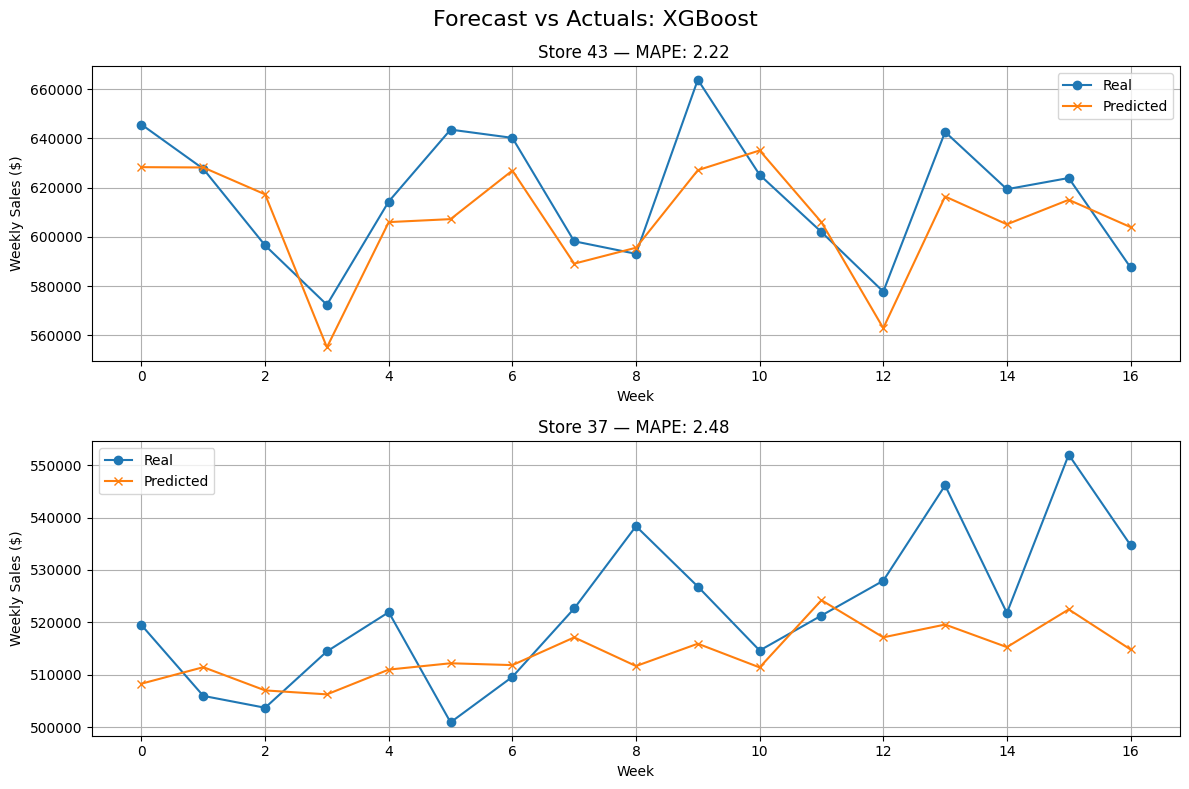

In [ ]:
import ast
import matplotlib.pyplot as plt

# Read results saved by the main cell
results_df = pd.read_csv(OUTPUT_FILE)

# Parse stringified lists into actual lists
for col in ("pred", "real"):
    if col in results_df.columns:
        results_df[col] = results_df[col].apply(lambda s: ast.literal_eval(s) if pd.notna(s) else [])

target_stores = [43, 37]
found = results_df[results_df['Store ID'].isin(target_stores)]

if found.empty:
    print(f"No results found for stores: {target_stores}")
else:
    n = len(found)
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(12, 4 * n), sharex=False)
    if n == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, found.iterrows()):
        store_id = row['Store ID']
        mape = row['MAPE (%)']
        real = row.get('real', [])
        pred = row.get('pred', [])
        x = range(len(real))
        ax.plot(x[:17], real[-17:], label='Real', marker='o')
        ax.plot(x[:17], pred[-17:], label='Predicted', marker='x')
        ax.set_title(f"Store {store_id} — MAPE: {mape} ")
        ax.set_xlabel("Week")
        ax.set_ylabel("Weekly Sales ($)")
        ax.legend()
        ax.grid(True)
    
    plt.suptitle('Forecast vs Actuals: XGBoost', fontsize=16)
    plt.tight_layout()
    plt.show()